# Week 7 - Support Vector Machine (SVM) Introduction

Support Vector Machine (SVM) is a supervised learning model used for classification and regression tasks. The objective of SVM is to find a hyperplane in an N-dimensional space (N = number of features) that distinctly classifies the data points.
<img src="./figures/svm1.png" alt="Alt text" width="400" height="300" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;">Figure: which linear separator is optimal?</p>

[image reference](https://people.csail.mit.edu/dsontag/courses/ml16/slides/lecture3.pdf)

## 1. Linear SVM

Consider a binary classification problem where we have training data points $ (\mathbf{x}_i, y_i) $ for $i = 1, 2, \dots, n$, where $ \mathbf{x}_i \in \mathbb{R}^d$ is the input data point and $y_i \in \{-1, 1\}$ is the corresponding label.

SVM aims to find a hyperplane that separates the data points with the largest margin. The hyperplane can be defined by:

$$
\mathbf{w}^T \mathbf{x} + b = 0
$$
where $ \mathbf{w} \in \mathbb{R}^d$ is the normal vector to the hyperplane, and $b$ is the bias term.

### SVM Optimization: minimize $\|\mathbf{w}\|^2$

The reason **Support Vector Machines (SVM)** minimize the norm of the weight vector $\mathbf{w} $, or equivalently $\|\mathbf{w}\|^2 $, is directly related to the concept of **maximizing the margin** between the two classes in a classification problem.
<img src="./figures/svm2.png" alt="Alt text" width="400" height="300" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;">Support Vectors are the data points that lie closest to the decision boundary (the hyperplane) in a support vector machine (SVM). The distance between the decision boundary and these nearest data points is called the margin</p>

[image reference](https://people.csail.mit.edu/dsontag/courses/ml16/slides/lecture3.pdf)

#### Key Idea: Maximizing the Margin

The **margin** is the distance between the decision boundary (the hyperplane) and the nearest data points, called **support vectors**. The goal of SVM is to find the hyperplane that best separates the two classes while ensuring the margin is as wide as possible.

The wider the margin, the more confidently the model can classify new points, leading to better generalization on unseen data.

#### Margin and the Weight Vector

Consider the decision function of a linear SVM:

$$
f(\mathbf{x}) = \mathbf{w}^\top \mathbf{x} + b
$$

The equation$ \mathbf{w}^\top \mathbf{x} + b = 0 $ defines the hyperplane separating the two classes. The **distance** $d $ from a point $ \mathbf{x}$ to this hyperplane is given by:

$$
d = \frac{| \mathbf{w}^\top \mathbf{x} + b |}{\|\mathbf{w}\|}
$$
If you have questions regarding the distance formula, please check this [reference](https://en.wikipedia.org/wiki/Distance_from_a_point_to_a_line)

- Thus, the distance from any point to the hyperplane is **inversely proportional** to the norm of $\mathbf{w}$. If $\|\mathbf{w}\|$ is smaller, the distance between the hyperplane and the support vectors is larger, meaning the margin is wider.

- Since the margin is proportional to $\frac{1}{\|\mathbf{w}\|}$, to maximize the margin, we need to **minimize** $\|\mathbf{w}\|$. This can be framed as minimizing the square of the norm, $\|\mathbf{w}\|^2$, to simplify the optimization problem.

- **minimizing $\|\mathbf{w}\|^2$ corresponds to maximizing the margin, which is the key idea behind SVM**. This also makes the SVM model robust to noise and reduces the risk of overfitting, as a larger margin implies more separation between classes.

#### Primal Objective

To summarize, the SVM optimization problem is formulated as:

$$
\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to} \quad y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1, \, \forall i
$$

This objective seeks to:
- Minimize $\|\mathbf{w}\|^2$ to maximize the margin (through regularization).
- **Ensure that the data points are correctly classified with a margin of at least 1**.

#### Geometric Interpretation

By minimizing the norm of $\mathbf{w}$, SVM aims to flatten the separating hyperplane. A smaller norm means that the hyperplane is positioned farther away from the data points (support vectors), leading to a larger margin and better generalization.

#### Why Maximize the Margin?

- **Generalization**: A large margin helps the model generalize better to unseen data.
- **Robustness**: It makes the model less sensitive to noise in the training data.
- **Separation**: A large margin maximizes the separation between the classes, reducing classification errors.

In conclusion, minimizing the weight vector $\|\mathbf{w}\|^2$ is directly linked to maximizing the margin, which is the central idea behind SVM.


### 1.1. Hard-Margin SVM (linear separable)

<img src="./figures/svm3.png" alt="Alt text" width="300" height="200" style="display: block; margin-left: auto; margin-right: auto;">

[image reference](https://people.csail.mit.edu/dsontag/courses/ml16/slides/lecture3.pdf)

- If $y_i$ is in class $+1$, $(\mathbf{w}^T \mathbf{x}_i + b) \geq 1, \quad \forall i$
- If $y_i$ is in class $-1$, $(\mathbf{w}^T \mathbf{x}_i + b) \leq -1, \quad \forall i$

The SVM optimization problem can be formulated as minimizing the norm of the weight vector $\mathbf{w}$, subject to the classification constraint:
$$
\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2
$$

subject to:

$$
y_i (\mathbf{w}^T \mathbf{x}_i + b) \geq 1, \quad \forall i
$$

This formulation is called **hard-margin SVM** and works well for linearly separable data.

### 1.2. Soft-Margin SVM

<img src="./figures/svm4.png" alt="Alt text" width="300" height="250" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;">Not linearly separable dataset</p>

[image reference](https://people.csail.mit.edu/dsontag/courses/ml16/slides/lecture3.pdf)
In cases where the data is not perfectly linearly separable, we introduce slack variables $\xi_i \geq 0$ to allow some misclassification:

$$
y_i (\mathbf{w}^T \mathbf{x}_i + b) \geq 1 - \xi_i, \quad \forall i
$$

- Correct classification, if $y_i (\mathbf{w}^T \mathbf{x}_i + b) \geq 1$, then $\xi_i=0$.
- Wrong classification, if $y_i (\mathbf{w}^T \mathbf{x}_i + b) < 1$, then $\xi_i= 1-y_i (\mathbf{w}^T \mathbf{x}_i + b)$

The objective becomes:
$$
\min_{\mathbf{w}, b, \xi} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^m \xi_i
$$

where $C$ is a regularization parameter that controls the trade-off between maximizing the margin and minimizing classification errors.

<img src="./figures/svm5.png" alt="Alt text" width="300" height="250" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;">Slack variables</p>

[image reference](https://people.csail.mit.edu/dsontag/courses/ml16/slides/lecture3.pdf)
## 2. SVM Loss Function

The **Support Vector Machine (SVM)** is a powerful classification algorithm. It works by finding a **hyperplane** that maximizes the margin between two classes in the feature space. The key idea behind SVM is to maximize the margin while minimizing the classification error, which is captured in its **loss function**.

### Primal Form of SVM Optimization

In its primal form, the optimization problem for SVM is defined as:

$$
\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to} \quad y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1, \, \forall i
$$

- $\mathbf{w}$ is the weight vector defining the hyperplane.
- $b$ is the bias term.
- $\mathbf{x}_i$ is the $i$-th input sample.
- $y_i \in \{-1, 1\} $ is the label for the $i$-th sample.

The objective is to **minimize** the **norm** of the weight vector $ \|\mathbf{w}\|^2 $, which is equivalent to maximizing the margin between the classes.

### Soft Margin SVM and the Hinge Loss

For non-linearly separable data, **soft margin SVM** introduces **slack variables** $ \xi_i$ to allow some misclassifications. The optimization problem becomes:

$$
\min_{\mathbf{w}, b, \xi} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^n \xi_i \quad \text{subject to} \quad y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1 - \xi_i, \, \forall i
$$

- $C$ is the **regularization parameter** controlling the trade-off between maximizing the margin and minimizing the error.
- $\xi_i \geq 0$ are the **slack variables** representing how much the samples violate the margin.

The **hinge loss** function is commonly used in SVM to quantify the misclassification:

$$
L_{\text{hinge}}(\mathbf{w}, b) = \sum_{i=1}^{n} \max(0, 1 - y_i(\mathbf{w}^\top \mathbf{x}_i + b))
$$

- If the sample is correctly classified (i.e., $ y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1 $), the loss is **zero**.
- If the sample is misclassified or within the margin (i.e., $ y_i(\mathbf{w}^\top \mathbf{x}_i + b) < 1 $), the loss grows linearly.

The **total loss** function for soft-margin SVM can be written as:

$$
L_{\text{SVM}}(\mathbf{w}, b) = \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^{n} \max(0, 1 - y_i(\mathbf{w}^\top \mathbf{x}_i + b))
$$


## 3. Kernel SVM

For nonlinearly separable data, SVM can be extended to handle nonlinear decision boundaries by using the **kernel trick**. The idea is to map the input features $\mathbf{x}_i$ to a higher-dimensional space via a function $\phi(\mathbf{x}_i)$, where the data becomes linearly separable.

The decision function in the feature space is:

$$
f(\mathbf{x}) = \mathbf{w}^T \phi(\mathbf{x}) + b
$$

Rather than computing $\phi(\mathbf{x})$ explicitly, we use a kernel function $ K(\mathbf{x}_i, \mathbf{x}_j)$ that computes the inner product in the feature space:

$$
K(\mathbf{x}_i, \mathbf{x}_j) = \phi(\mathbf{x}_i)^T \phi(\mathbf{x}_j)
$$

Common kernel functions include:

- **Linear Kernel**: $K(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^T \mathbf{x}_j $
- **Polynomial Kernel**: $K(\mathbf{x}_i, \mathbf{x}_j) = (\mathbf{x}_i^T \mathbf{x}_j + c)^d $
- **Radial Basis Function (RBF) Kernel**: 

$$
K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left(-\frac{\|\mathbf{x}_i - \mathbf{x}_j\|^2}{2 \sigma^2}\right)
$$

### Dual Formulation

The optimization problem for SVM can also be written in its **dual form** using Lagrange multipliers $\alpha_i$:

$$
\max_{\alpha} \sum_{i=1}^m \alpha_i - \frac{1}{2} \sum_{i=1}^m \sum_{j=1}^m \alpha_i \alpha_j y_i y_j K(\mathbf{x}_i, \mathbf{x}_j)
$$

subject to:

$$
0 \leq \alpha_i \leq C, \quad \sum_{i=1}^m \alpha_i y_i = 0
$$

The decision function becomes:

$$
f(\mathbf{x}) = \sum_{i=1}^m \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b
$$

Only a subset of the training points, called **support vectors**, have nonzero $\alpha_i$. These points lie on the margin and define the decision boundary.

## 4. Decision Boundary and Support Vectors

The decision boundary is determined by the support vectors, which are the data points that lie closest to the hyperplane. In the case of kernel SVM, the decision boundary may be nonlinear, depending on the kernel function used.

The margin is the distance between the hyperplane and the nearest data point. The goal of SVM is to maximize this margin.


## 5. SVM vs.Linear Logistic Regression 

Logistic regression and Support Vector Machines (SVM) are both popular classification techniques in machine learning. They both aim to classify data points into categories, but they differ in how they approach this problem.

### Logistic Regression Overview

Logistic Regression is a probabilistic model used for binary classification. It models the probability that a given data point belongs to a particular class, usually labeled as $0$ or $1$. The decision boundary is determined by the **sigmoid** function applied to a linear combination of the features.

The logistic regression model predicts the probability $ P(y = 1 \mid \mathbf{x}) $ using the following model:
$$
P(y = 1 \mid \mathbf{x}) = \frac{1}{1 + \exp(-(\mathbf{w}^T \mathbf{x} + b))}
$$

where $\mathbf{w}$ is the weight vector, $\mathbf{x}$ is the feature vector, and $b$ is the bias term. The model's decision is made based on the probability $P(y = 1 \mid \mathbf{x}) $:

$$
\hat{y} = \begin{cases}
1, & \text{if } P(y = 1 \mid \mathbf{x}) > 0.5 \\
0, & \text{otherwise}
\end{cases}
$$

### Optimization in Logistic Regression

Logistic regression is optimized using the **maximum likelihood estimation (MLE)**. The cost function for logistic regression is the **logistic loss function**:

$$
\text{Logistic Loss} = - \frac{1}{m} \sum_{i=1}^{m} \left[ y_i \log(h_\theta(\mathbf{x}_i)) + (1 - y_i) \log(1 - h_\theta(\mathbf{x}_i)) \right]
$$

where $h_\theta(\mathbf{x}_i)$ is the predicted probability that $y = 1$.

### Optimization in SVM 

Support Vector Machines (SVM) are non-probabilistic models used for binary classification. SVM finds a **hyperplane** that maximizes the margin between two classes, aiming to maximize the distance between the decision boundary and the nearest data points (called **support vectors**).


For a binary classification problem with two classes $ y_i \in \{-1, 1\} $, the SVM finds the hyperplane defined by:
$$
\mathbf{w}^T \mathbf{x} + b = 0
$$

SVM solves an optimization problem to maximize the margin between the two classes. The optimization problem is:
$$
\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2
$$

subject to:

$$
y_i (\mathbf{w}^T \mathbf{x}_i + b) \geq 1, \quad \forall i
$$

This is the **hard-margin SVM**. For non-linearly separable data, the **soft-margin SVM** introduces slack variables $ \xi_i $ to allow some misclassification:

$$
y_i (\mathbf{w}^T \mathbf{x}_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0
$$

### Decision Function

The decision function for SVM is:

$$
f(\mathbf{x}) = \mathbf{w}^T \mathbf{x} + b
$$

where the sign of $ f(\mathbf{x})$ determines the predicted class. If $f(\mathbf{x}) > 0$, then the predicted class is $+1$; otherwise, it is $-1$.

## Key Differences Between Logistic Regression and SVM

### Objective
- **Logistic Regression**: Maximizes the likelihood of the observed data by modeling the probability of the outcomes using the sigmoid function. The decision boundary is based on a threshold, usually 0.5.
- **SVM**: Maximizes the margin between the two classes by finding a hyperplane that separates the data points. The decision boundary is determined by support vectors.

### Decision Boundary
- **Logistic Regression**: Provides a **probabilistic** interpretation of the output. The decision boundary is soft, meaning the probability of belonging to a class is gradually adjusted depending on the input.
- **SVM**: Provides a **deterministic** classification, with a hard decision boundary that separates the data points with maximum margin.

### Handling of Outliers
- **Logistic Regression**: Outliers can significantly affect the decision boundary since logistic regression attempts to fit the data as a whole.
- **SVM**: The decision boundary depends only on support vectors. Therefore, outliers not near the boundary have less impact.

### Loss Function
- **Logistic Regression**: Uses the **logistic loss** (cross-entropy loss) function.
- **SVM**: Uses the **hinge loss** function, which only penalizes points that are on the wrong side of the margin.
$$
\text{Hinge Loss} = \max(0, 1 - y_i (\mathbf{w}^T \mathbf{x}_i + b))
$$

### Kernelization
- **Logistic Regression**: Generally operates in the input space and does not support kernelization.
- **SVM**: Can be extended to **Kernel SVM** by using a kernel function $ K(\mathbf{x}_i, \mathbf{x}_j) $ that maps the input features to a higher-dimensional space, enabling SVM to handle non-linear decision boundaries.

### When to Use Logistic Regression vs. SVM?

- **Logistic Regression**: Preferred for problems where the data is linearly separable and a probabilistic interpretation is required.
- **SVM**: Preferred when you need a hard decision boundary, especially if the data is not linearly separable. SVM can also be extended with kernel functions to handle non-linear boundaries.

## 5. Conclusion

Both Logistic Regression and SVM are widely used for binary classification tasks. Logistic regression is a probabilistic model, while SVM focuses on maximizing the margin between two classes. SVM can be more effective in handling outliers and can be extended to nonlinear problems using the kernel trick. 


Starting 2-Class SVC demonstration with explicit marginal boundaries...


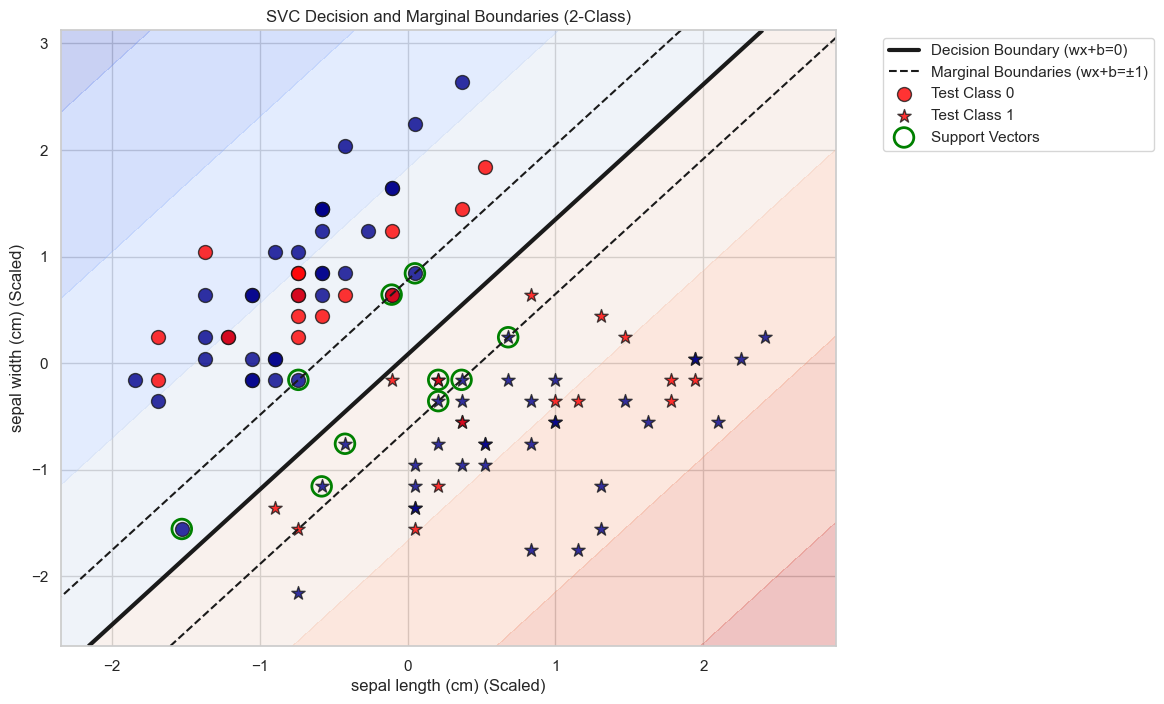


SVC demo finished. Check the plot: The solid black line is the Decision Boundary, and the dashed black lines are the Marginal Boundaries defined by the Support Vectors (green circles).


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC 

# --- Configuration ---
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 8)
print("Starting 2-Class SVC demonstration with explicit marginal boundaries...")

# --- 1. Data Loading and Filtering (Focusing on two classes: 0 and 1) ---
iris = datasets.load_iris()

# Use only the first two features (Sepal Length and Sepal Width)
X_full = iris.data[:, :2] 
y_full = iris.target

# Filter data to include only classes 0 and 1 (Setosa and Versicolor)
X = X_full[y_full < 2]
y = y_full[y_full < 2]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=42, 
    stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 2. Model Training ---
# Use a linear kernel for clear boundary visualization
svm = SVC(kernel='linear', C=1.0, random_state=42)
svm.fit(X_train_scaled, y_train)

# Combine scaled train and test data for plotting the decision regions over the whole space
X_combined = np.vstack((X_train_scaled, X_test_scaled))
y_combined = np.hstack((y_train, y_test))

# --- 3. Plotting Decision Boundaries and Points ---

def plot_boundaries(X, y, model, title):
    # Determine the boundaries for the plot grid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    
    # Create mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    # Get the decision function output for every point in the mesh (this is wx + b)
    # The decision function output is Z
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot the decision regions (color filling)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    
    # PLOT THE BOUNDARIES:
    # 1. Decision Boundary (where wx + b = 0) - Solid black line
    plt.contour(xx, yy, Z, levels=[0], colors='k', linestyles=['-'], linewidths=3)
    
    # 2. Marginal Boundaries (where wx + b = -1 and wx + b = +1) - Dashed lines
    plt.contour(xx, yy, Z, levels=[-1, 1], colors='k', linestyles=['--'], linewidths=1.5)
    
    # --- Marker and Color Definitions ---
    markers = ['o', '*'] # Circle for Class 0, Star for Class 1
    train_color = 'darkblue'
    test_color = 'red'
    
    # Plotting TRAINING points
    for i in np.unique(y_train):
        X_i = X_train_scaled[y_train == i]
        plt.scatter(
            X_i[:, 0], X_i[:, 1], 
            c=train_color, 
            marker=markers[i], 
            s=100, 
            edgecolor='k',
            alpha=0.8,
            label=f'Train Class {i}'
        )
        
    # Plotting TESTING points
    for i in np.unique(y_test):
        X_i = X_test_scaled[y_test == i]
        plt.scatter(
            X_i[:, 0], X_i[:, 1], 
            c=test_color, 
            marker=markers[i], 
            s=100, 
            edgecolor='k',
            alpha=0.8,
            label=f'Test Class {i}'
        )

    # Highlight the Support Vectors
    sv = model.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='green', 
                linewidth=2, label='Support Vectors')

    plt.xlabel(iris.feature_names[0] + " (Scaled)")
    plt.ylabel(iris.feature_names[1] + " (Scaled)")
    plt.title(title)
    
    # Manually create legend elements for the lines
    h_decision = plt.Line2D([0], [0], color='k', linestyle='-', linewidth=3, label='Decision Boundary (wx+b=0)')
    h_margin = plt.Line2D([0], [0], color='k', linestyle='--', linewidth=1.5, label='Marginal Boundaries (wx+b=±1)')

    # Add all legend elements
    handles, labels = plt.gca().get_legend_handles_labels()
    handles = [h_decision, h_margin] + handles[-3:] # Ensure line elements come first
    labels = ['Decision Boundary (wx+b=0)', 'Marginal Boundaries (wx+b=±1)'] + labels[-3:]

    plt.legend(handles=handles, labels=labels, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

# --- 4. Display Plot ---
plt.figure()
plot_boundaries(X_combined, y_combined, svm, 'SVC Decision and Marginal Boundaries (2-Class)')
plt.show()

print("\nSVC demo finished. Check the plot: The solid black line is the Decision Boundary, and the dashed black lines are the Marginal Boundaries defined by the Support Vectors (green circles).")
